| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_2_PINNs.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_4_Reduced_Order_Modeling.ipynb) |

# 15.3 Neural Operators: aprender transformaciones entre funciones

Hasta ahora una red recibía coordenadas y aproximaba una solución. Un operador neuronal recibe información sobre **una función completa** y predice otra función. Construiremos un operador espectral entrenable para una familia de problemas de difusión, lo evaluaremos con funciones nuevas y cambiaremos la resolución de la malla.

**Objetivos:** distinguir función y operador; preparar pares de campos sin fuga de datos; comprender Fourier y DeepONet; verificar generalización entre funciones y resoluciones. **Prerrequisitos:** 5.4 Fourier, 8.1 PDE y 12.1 redes. **Librerías:** NumPy, Matplotlib y PyTorch. Los ejemplos usan CPU y datos sintéticos.

## 1. Función, solución y operador de solución

Una función $u(x)$ asigna un valor a una coordenada. Un operador $\mathcal G$ transforma una función de entrada $a$ en una función de salida:

$$\mathcal G:a(\cdot)\mapsto u(\cdot).$$

Por ejemplo, en la difusión $u_t=\alpha u_{xx}$, fijamos $\alpha$, dominio y tiempo final $T$. Cada condición inicial $a(x)=u(x,0)$ produce un estado final distinto. El operador de solución es

$$\mathcal G_T[a](x)=u(x,T).$$

La coordenada $x$ localiza una salida; la función $a$ define cuál experimento estamos resolviendo. No confundas varios puntos de la misma solución con varias funciones independientes de entrenamiento.

Un surrogate que predice una temperatura desde dos parámetros también puede ser útil. Se habla de aprendizaje de operadores cuando la entrada y la salida se plantean como elementos de espacios de funciones, aunque en el ordenador siempre se representen con muestras o coeficientes finitos.

## 2. Una familia de PDE con referencia espectral

Trabajaremos en $x\in[0,1)$ con condiciones periódicas. Escribimos

$$a(x)=a_0+\sum_{j=1}^K[A_j\cos(2\pi jx)+B_j\sin(2\pi jx)].$$

Como $\partial_{xx}\cos(2\pi jx)=-(2\pi j)^2\cos(2\pi jx)$, cada modo decae independientemente:

$$\widehat u_j(T)=e^{-\alpha(2\pi j)^2T}\widehat a_j.$$

Por tanto, el operador de calor es un multiplicador de Fourier. Los modos de frecuencia alta desaparecen más rápido y el modo constante se conserva. Usaremos $\alpha=0.1$, $T=0.02$ y condiciones iniciales con hasta ocho modos.

La periodicidad importa: una FFT trata el campo como periódico. No puede utilizarse sin cambios para una barra con extremos de Dirichlet. Para geometrías o condiciones distintas se requieren extensiones, otras bases o arquitecturas apropiadas.

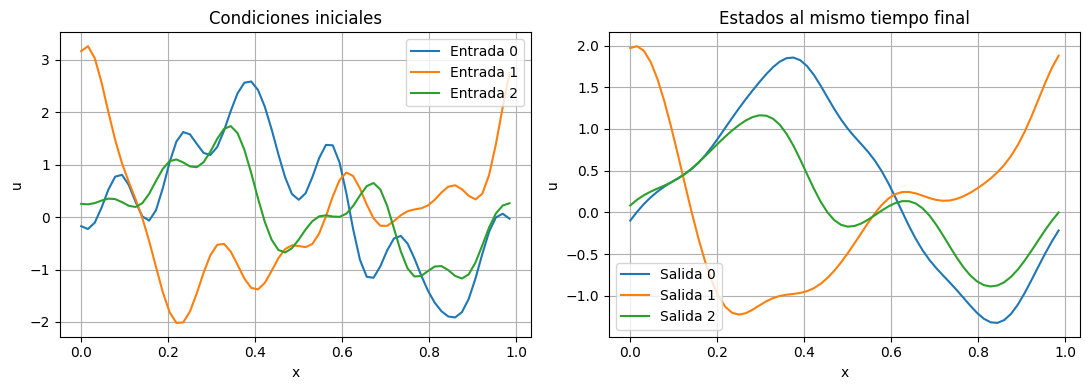

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
torch.manual_seed(153)
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(153)
alpha, T_final = 0.1, 0.02
K_datos = 8
def generar_coeficientes(n):
    # Mismas distribuciones para train/test, realizaciones independientes.
    media = rng.normal(0, 0.2, (n, 1))
    amplitudes = rng.normal(size=(n, 2, K_datos))/np.arange(1, K_datos+1)[None,None,:]
    return media, amplitudes

def campos(coefs, n_grid, evolucionar=False):
    media, amplitudes = coefs
    x = np.arange(n_grid)/n_grid  # No duplicar x=0 y x=1 en la FFT.
    modos = np.arange(1, K_datos+1)
    fase = 2*np.pi*modos[:,None]*x[None,:]
    dec = np.exp(-alpha*(2*np.pi*modos)**2*T_final) if evolucionar else np.ones(K_datos)
    u = media + (amplitudes[:,0,:]*dec)@np.cos(fase) + (amplitudes[:,1,:]*dec)@np.sin(fase)
    return x, u

coefs_train = generar_coeficientes(128)
coefs_test = generar_coeficientes(32)
x, a_train = campos(coefs_train, 64)
_, u_train = campos(coefs_train, 64, True)
_, a_test = campos(coefs_test, 64)
_, u_test = campos(coefs_test, 64, True)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for i in range(3):
    axes[0].plot(x, a_train[i], label=f'Entrada {i}')
    axes[1].plot(x, u_train[i], label=f'Salida {i}')
for ax, title in zip(axes, ['Condiciones iniciales', 'Estados al mismo tiempo final']):
    ax.set(xlabel='x', ylabel='u', title=title); ax.legend(); ax.grid()
plt.tight_layout(); plt.show()

## 3. La unidad de separación es la función

Tenemos 128 pares de funciones para entrenamiento y 32 pares distintos para prueba. Cada fila contiene 64 valores espaciales. Separar columnas de una misma fila entre train y test mediría interpolación espacial de experimentos ya vistos, no generalización a condiciones iniciales nuevas.

La referencia se calcula directamente con los coeficientes analíticos de cada función; por eso no introduce error de integración temporal. En aplicaciones reales, las etiquetas pueden provenir de solvers con error de discretización. Un operador aprendido puede heredar ese error o aprender regularidades del generador.

Las funciones de prueba provienen de la misma distribución. Esto evalúa generalización dentro de una familia; no asegura comportamiento con discontinuidades, otras condiciones de borde o valores diferentes de $\alpha$ y $T$.

## 4. Un operador neuronal espectral mínimo

Aprenderemos pesos $w_j$ para construir

$$\mathcal G_\theta[a]=\operatorname{irFFT}(w_\theta\odot\operatorname{rFFT}(a)).$$

Para nuestro problema lineal, pesos reales son suficientes. Esta capa es un **operador lineal entrenable en Fourier**, una versión mínima que permite entender la operación central. Una FNO completa suele añadir canales, mezclas entre canales, transformaciones locales y activaciones no lineales. No llamaremos FNO completa a una sola multiplicación diagonal.

Conservaremos nueve modos: el constante y los ocho del generador. Los demás se ponen a cero. Esta elección contiene una hipótesis sobre la regularidad y el ancho de banda de los datos. Los pesos no tienen un eje dependiente del número de puntos de malla, lo que permite reutilizarlos al cambiar resolución dentro de sus modos representables.

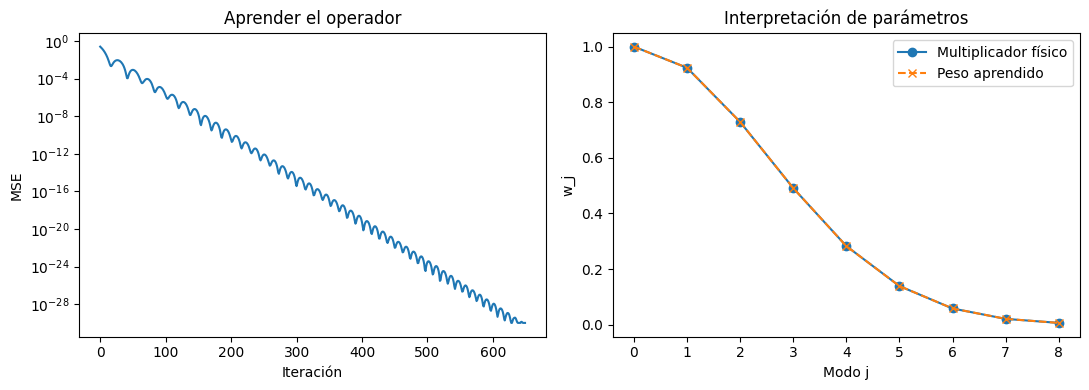

In [2]:
class OperadorEspectral(nn.Module):
    def __init__(self, n_modos):
        super().__init__()
        self.n_modos = n_modos
        self.pesos = nn.Parameter(torch.full((n_modos,), 0.5))
    def forward(self, entrada):
        espectro = torch.fft.rfft(entrada, dim=-1, norm='forward')
        m = min(self.n_modos, espectro.shape[-1])
        salida_hat = torch.zeros_like(espectro)
        salida_hat[..., :m] = espectro[..., :m]*self.pesos[:m]
        return torch.fft.irfft(salida_hat, n=entrada.shape[-1], dim=-1, norm='forward')

operador = OperadorEspectral(K_datos+1)
A = torch.tensor(a_train)
U = torch.tensor(u_train)
opt = torch.optim.Adam(operador.parameters(), lr=0.03)
hist = []
for _ in range(650):
    opt.zero_grad(set_to_none=True)
    loss = ((operador(A)-U)**2).mean()
    loss.backward(); opt.step(); hist.append(loss.item())
modos = np.arange(K_datos+1)
pesos_exactos = np.exp(-alpha*(2*np.pi*modos)**2*T_final)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(np.maximum(hist, 1e-30)); ax[0].set(xlabel='Iteración', ylabel='MSE', title='Aprender el operador')
ax[1].plot(modos, pesos_exactos, 'o-', label='Multiplicador físico')
ax[1].plot(modos, operador.pesos.detach().numpy(), 'x--', label='Peso aprendido')
ax[1].set(xlabel='Modo j', ylabel='w_j', title='Interpretación de parámetros')
ax[1].legend(); plt.tight_layout(); plt.show()

## 5. Qué aprendió el modelo

La comparación de pesos permite evaluar el mecanismo además de la salida. En este caso, recuperar $w_j$ tiene una interpretación física directa: estimar la atenuación de cada modo al tiempo fijado.

Si un modo nunca aparece en las entradas, su peso no es identificable a partir de la pérdida supervisada. Si aparece con amplitud extremadamente pequeña, afecta poco al MSE total y puede aprenderse con menor precisión. Esto conecta distribución de entrenamiento, identificabilidad y elección de norma.

El error de entrenamiento puede llegar a precisión de redondeo porque el operador físico pertenece a la familia del modelo. Una PDE no lineal o coeficientes espaciales variables no tendrían generalmente este multiplicador diagonal fijo.

Error relativo medio en funciones nuevas: 4.554462505862321e-16
Error relativo máximo: 6.892794667072395e-16


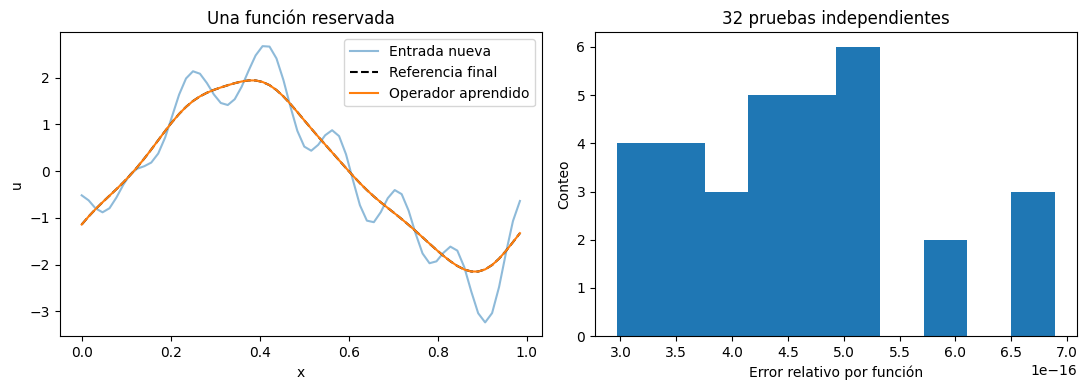

In [3]:
with torch.no_grad():
    pred_test = operador(torch.tensor(a_test)).numpy()
errores_rel = np.linalg.norm(pred_test-u_test, axis=1)/np.linalg.norm(u_test, axis=1)
print('Error relativo medio en funciones nuevas:', errores_rel.mean())
print('Error relativo máximo:', errores_rel.max())
assert errores_rel.max() < 1e-4
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, a_test[0], alpha=0.5, label='Entrada nueva')
axes[0].plot(x, u_test[0], 'k--', label='Referencia final')
axes[0].plot(x, pred_test[0], label='Operador aprendido')
axes[0].set(xlabel='x', ylabel='u', title='Una función reservada'); axes[0].legend()
axes[1].hist(errores_rel, bins=10)
axes[1].set(xlabel='Error relativo por función', ylabel='Conteo', title='32 pruebas independientes')
plt.tight_layout(); plt.show()

## 6. Cambiar la resolución sin volver a entrenar

Evaluaremos las **mismas funciones de prueba** en 128 puntos en lugar de 64. Para hacerlo correctamente usamos sus coeficientes originales; interpolar primero las salidas de 64 puntos no probaría la transferencia del operador sobre entradas de mayor resolución.

La FFT representa frecuencias $j$ físicas iguales cuando la longitud del dominio permanece uno. El uso consistente de `norm='forward'` permite interpretar los coeficientes sin una escala accidental por el tamaño de malla. Conservamos también la convención de puntos periódicos sin duplicar el extremo.

La transferencia funcionará porque los datos solo contienen ocho modos, bien resueltos en ambas mallas, y nuestro operador actúa sobre esos mismos modos. Esto no prueba que una red pueda recuperar frecuencias nunca observadas o que cualquier operador sea independiente de discretización.

Malla 64: error medio 4.554462505862321e-16
Malla 128 sin reentrenar: error medio 4.489311279174046e-16


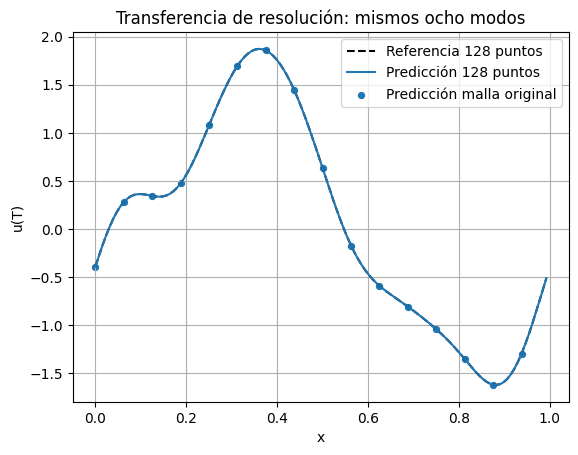

In [4]:
x_fino, a_fino = campos(coefs_test, 128)
_, u_fino = campos(coefs_test, 128, True)
with torch.no_grad(): p_fino = operador(torch.tensor(a_fino)).numpy()
err_fino = np.linalg.norm(p_fino-u_fino, axis=1)/np.linalg.norm(u_fino, axis=1)
print('Malla 64: error medio', errores_rel.mean())
print('Malla 128 sin reentrenar: error medio', err_fino.mean())
plt.plot(x_fino, u_fino[1], 'k--', label='Referencia 128 puntos')
plt.plot(x_fino, p_fino[1], label='Predicción 128 puntos')
plt.scatter(x[::4], pred_test[1, ::4], s=18, label='Predicción malla original')
plt.xlabel('x'); plt.ylabel('u(T)'); plt.title('Transferencia de resolución: mismos ocho modos')
plt.legend(); plt.grid(); plt.show()
assert err_fino.max() < 1e-4

## 7. Una prueba fuera de la distribución

Introduzcamos el modo 12, que no existe en el generador de entrenamiento ni en los pesos retenidos. El modelo lo elimina, mientras que la solución física todavía conserva una amplitud $e^{-\alpha(2\pi12)^2T}$.

No basta medir error relativo sobre casos fáciles: también hay que diseñar pruebas que contradigan una hipótesis del entrenamiento. La difusión fuerte puede ocultar el fallo al reducir casi completamente las frecuencias altas. Para un transporte sin difusión, omitir un modo conservaría un error mucho mayor.

Error relativo fuera del ancho de banda: 1.0


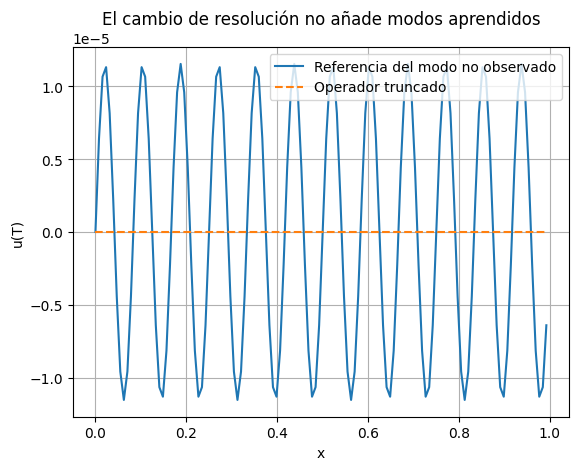

In [5]:
j_nuevo = 12
a_fuera = np.sin(2*np.pi*j_nuevo*x_fino)
u_fuera = np.exp(-alpha*(2*np.pi*j_nuevo)**2*T_final)*a_fuera
with torch.no_grad(): p_fuera = operador(torch.tensor(a_fuera[None,:])).numpy().ravel()
rel_fuera = np.linalg.norm(p_fuera-u_fuera)/np.linalg.norm(u_fuera)
plt.plot(x_fino, u_fuera, label='Referencia del modo no observado')
plt.plot(x_fino, p_fuera, '--', label='Operador truncado')
plt.xlabel('x'); plt.ylabel('u(T)'); plt.title('El cambio de resolución no añade modos aprendidos')
plt.legend(); plt.grid(); plt.show()
print('Error relativo fuera del ancho de banda:', rel_fuera)

## 8. Cómo se construye un bloque FNO

Una capa con varios canales aplica

$$v_{\ell+1}(x)=\sigma\left(W_\ell v_\ell(x)+
\mathcal F^{-1}\left[R_\ell(j)\mathcal F[v_\ell](j)\right](x)\right).$$

$W_\ell$ mezcla canales en cada punto. $R_\ell(j)$ es una matriz compleja entrenable por modo y mezcla canales en Fourier. La transformada inversa devuelve un campo, y $\sigma$ añade no linealidad. Una arquitectura completa comienza elevando el número de canales y termina proyectando a las variables de salida.

La siguiente implementación demuestra un bloque y verifica que admite dos resoluciones. **Sus parámetros están sin entrenar**: solo probamos formas y gradientes. El operador que hemos entrenado arriba es el caso lineal diagonal, adecuado para nuestra ecuación; los resultados numéricos no corresponden a una FNO multicapa entrenada.

In [6]:
class BloqueFNO1D(nn.Module):
    def __init__(self, canales, modos):
        super().__init__()
        self.modos = modos
        escala = 1/canales
        self.R = nn.Parameter(escala*torch.randn(canales, canales, modos, dtype=torch.cdouble))
        self.local = nn.Conv1d(canales, canales, kernel_size=1)
    def forward(self, v):  # [batch, canales, puntos]
        vh = torch.fft.rfft(v, norm='forward')
        m = min(self.modos, vh.shape[-1])
        salida = torch.zeros_like(vh)
        salida[:,:,:m] = torch.einsum('bik,iok->bok', vh[:,:,:m], self.R[:,:,:m])
        global_ = torch.fft.irfft(salida, n=v.shape[-1], norm='forward')
        return torch.tanh(self.local(v)+global_)

bloque = BloqueFNO1D(canales=4, modos=9)
for n in [64, 128]:
    salida = bloque(torch.randn(2, 4, n))
    print('Resolución', n, '| forma de salida:', tuple(salida.shape))
salida.square().mean().backward()
print('Gradiente espectral finito:', torch.isfinite(bloque.R.grad).all().item())

Resolución 64 | forma de salida: (2, 4, 64)
Resolución 128 | forma de salida: (2, 4, 128)
Gradiente espectral finito: True


## 9. DeepONet: rama y tronco

DeepONet combina una red **branch**, que lee una función en sensores fijos, con una red **trunk**, que lee coordenadas de evaluación. Una forma básica es

$$\mathcal G_\theta[a](x)=\sum_{j=1}^p b_j(a(x_1),\ldots,a(x_m))\,t_j(x)+c.$$

Los coeficientes $b_j$ dependen de la función de entrada; los valores $t_j(x)$ dependen de la coordenada. El producto permite consultar la salida en distintas posiciones. Los sensores de entrada siguen siendo parte de la arquitectura: cambiar arbitrariamente su número requiere un encoder adecuado o una estrategia adicional.

Esta construcción recuerda a un modelo de orden reducido, pero aquí la representación puede aprenderse de manera no lineal y conjunta. La existencia de una aproximación expresiva no asegura encontrarla al entrenar ni generalizar a funciones nuevas.

In [7]:
class DeepONetMinimo(nn.Module):
    def __init__(self, sensores=64, p=16):
        super().__init__()
        self.branch = nn.Sequential(nn.Linear(sensores, 32), nn.Tanh(), nn.Linear(32, p))
        self.trunk = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, p))
        self.bias = nn.Parameter(torch.zeros(()))
    def forward(self, funciones, coordenadas):
        # Todas las funciones se consultan sobre el mismo conjunto de coordenadas.
        return self.branch(funciones)@self.trunk(coordenadas).T + self.bias

deep_demo = DeepONetMinimo()
salida_demo = deep_demo(torch.tensor(a_test[:2]), torch.tensor(x_fino[:,None]))
print('DeepONet sin entrenar: dos entradas, 128 consultas ->', tuple(salida_demo.shape))

DeepONet sin entrenar: dos entradas, 128 consultas -> (2, 128)


## 10. Pérdidas, normas y física

Una pérdida supervisada usual promedia error sobre funciones y coordenadas:

$$\mathcal L=\frac1N\sum_{i=1}^N
\frac{\|\mathcal G_\theta[a_i]-u_i\|_2^2}{\|u_i\|_2^2+\varepsilon}.$$

La normalización evita que casos de mayor amplitud dominen, pero una referencia casi nula exige cuidado con $\varepsilon$. Otras tareas necesitan una norma de Sobolev que incluya derivadas o una norma de energía ligada a la PDE.

Un operador también puede añadir residuos físicos, restricciones de conservación o condiciones de borde. Eso requiere poder evaluar las derivadas y la ecuación para cada función predicha. Aprender solo el estado a un tiempo final no proporciona directamente $u_t$; necesitaríamos una salida temporal o un operador de evolución con pasos apropiados.

En nuestro problema el promedio espacial se conserva, y el peso del modo constante debería ser uno. Puede comprobarse en los pesos o imponerse de antemano. Este tipo de estructura reduce grados de libertad, pero debe corresponder a la física real.


## 11. Coste y límites de uso

La FFT cuesta aproximadamente $O(n\log n)$ por campo; las mezclas de canales y modos añaden coste. La preparación del dataset y el entrenamiento forman una fase offline. Una predicción sobre una entrada nueva forma la fase online. Para decidir si compensa entrenar, considera cuántas consultas se realizarán y cuánto cuesta generar etiquetas fiables.

En esta PDE la fórmula espectral exacta ya es muy barata. El aprendizaje se usa como demostración, sin afirmar ahorro sobre el solver analítico. Para modelos complejos hay que incluir generación de datos, error, memoria y cambios de distribución en la comparación.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_2_PINNs.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_4_Reduced_Order_Modeling.ipynb) |